# Import

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow
import mlflow.sklearn
from pathlib import Path

# Load Data

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "heart_disease_clean.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values:", df.isna().sum().sum())
print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

Dataset shape: (303, 14)


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,63,145,233,150,2.3,1,1,1,2,0,3,0.0,6.0,0
1,67,160,286,108,1.5,1,4,0,2,1,2,3.0,3.0,1
2,67,120,229,129,2.6,1,4,0,2,1,2,2.0,7.0,1
3,37,130,250,187,3.5,1,3,0,0,0,3,0.0,3.0,0
4,41,130,204,172,1.4,0,2,0,2,0,1,0.0,3.0,0



Missing values: 0

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


# Separate Input Features and Target

In [3]:
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df["target"].astype(int)

assert set(y.unique()).issubset({0, 1})
assert "target" not in X.columns

print("Features:", X.shape)
print("Target:", y.shape)

Features: (303, 13)
Target: (303,)


# Splitting data into Training and Test Data set

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 242
Testing records: 61

Training class distribution:
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Testing class distribution:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


# PreProcessing Pipeline

In [5]:

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


# Define the model

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    for name, model in models.items()
}

print("Models ready:", list(pipelines.keys()))

Models ready: ['Logistic Regression', 'Random Forest']


# Train and evaluate with cross-validation

In [7]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results).set_index("Model")

display(cv_df.round(3))

,CV Accuracy,CV Precision,CV Recall,CV ROC-AUC
Model,,,,
Logistic Regression,0.847,0.877,0.783,0.902
Random Forest,0.806,0.802,0.765,0.894


# Hyperparameter tuning

In [8]:

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_leaf": [1, 3],
        "classifier__max_features": ["sqrt"]
    }
}

searches = {}
tuning_results = []

for name, pipeline in pipelines.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)
    searches[name] = search

    tuning_results.append({
        "Model": name,
        "Best CV ROC-AUC": search.best_score_,
        "Best Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results).set_index("Model")

display(tuning_df)

,Best CV ROC-AUC,Best Parameters
Model,,
Logistic Regression,0.902790,"{'classifier__C': 0.1, 'classifier__class_weig..."
Random Forest,0.902992,"{'classifier__max_depth': 5, 'classifier__max_..."


# Evaluate the models on the test set


Logistic Regression
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
                 precision    recall  f1-score   support

     No disease       0.93      0.85      0.89        33
Disease present       0.84      0.93      0.88        28

       accuracy                           0.89        61
      macro avg       0.89      0.89      0.89        61
   weighted avg       0.89      0.89      0.89        61


Random Forest
Best parameters: {'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}
                 precision    recall  f1-score   support

     No disease       0.90      0.85      0.88        33
Disease present       0.83      0.89      0.86        28

       accuracy                           0.87        61
      macro avg       0.87      0.87      0.87        61
   weighted avg       0.87      0.87      0.87        61



,Accuracy,Precision,Recall,ROC-AUC
Model,,,,
Logistic Regression,0.885,0.839,0.929,0.965
Random Forest,0.869,0.833,0.893,0.945


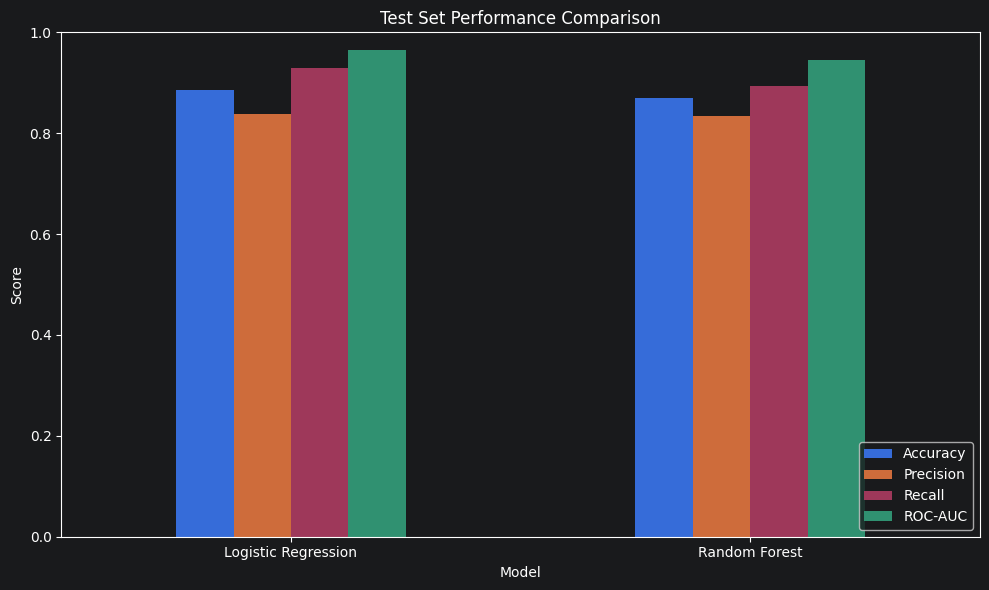

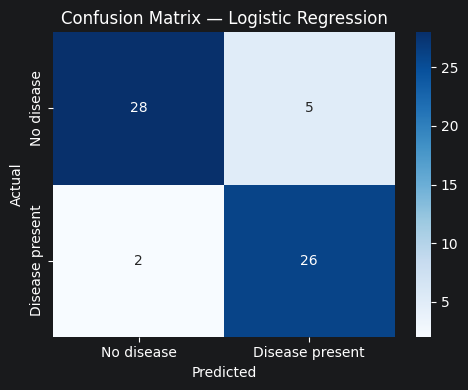

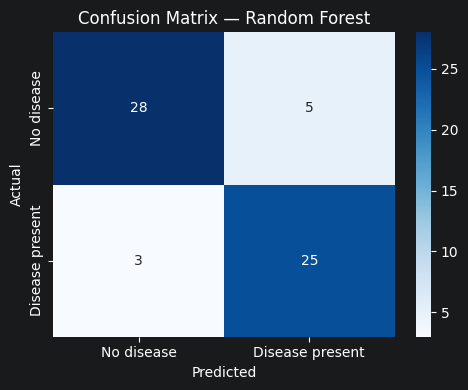

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

final_results = []
fitted_models = {}

for name, search in searches.items():
    best_model = search.best_estimator_
    fitted_models[name] = best_model

    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No disease", "Disease present"],
        zero_division=0
    ))

results_df = pd.DataFrame(final_results).set_index("Model")

display(results_df.round(3))


results_df.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Test Set Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures"
    / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No disease", "Disease present"],
        yticklabels=["No disease", "Disease present"]
    )

    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")
    plt.savefig(
        PROJECT_ROOT / "reports" / "figures"
        / f"confusion_matrix_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

# Final Output

In [10]:
best_model_name = max(
    searches,
    key=lambda name: searches[name].best_score_
)

best_search = searches[best_model_name]
best_model = best_search.best_estimator_

print("Selected model:", best_model_name)
print("Best cross-validation ROC-AUC:", best_search.best_score_)
print("Best parameters:", best_search.best_params_)

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

model_path = ARTIFACT_DIR / "heart_disease_pipeline.joblib"

joblib.dump(best_model, model_path)

print("Model pipeline saved to:", model_path)

results_df.to_csv(
    PROJECT_ROOT / "reports" / "model_evaluation.csv"
)

tuning_df.to_csv(
    PROJECT_ROOT / "reports" / "tuning_results.csv"
)

print("Evaluation reports saved.")

Selected model: Random Forest
Best cross-validation ROC-AUC: 0.9029920160354943
Best parameters: {'classifier__max_depth': 5, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 100}
Model pipeline saved to: D:\MTech\SEM3\MLOps\Assignment1\heart-disease-mlops\artifacts\heart_disease_pipeline.joblib
Evaluation reports saved.


# configuring ML Flow

In [11]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Store experiment records inside the project
TRACKING_DIR = PROJECT_ROOT / "mlruns"
TRACKING_DIR.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(TRACKING_DIR.as_uri())

# Create a named experiment
mlflow.set_experiment("Heart-Disease-Classification")

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Experiment configured successfully!")

MLflow tracking URI: file:///D:/MTech/SEM3/MLOps/Assignment1/heart-disease-mlops/mlruns
Experiment configured successfully!


# Adding metrics to ML Flow

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
from mlflow.models import infer_signature

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MODEL_PATH = PROJECT_ROOT / "artifacts" / "heart_disease_pipeline.joblib"

for name, search in searches.items():

    # Retrieve the best tuned pipeline for this model
    model = search.best_estimator_

    # Generate predictions on the held-out test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Prepare metrics
    metrics = {
        "cv_roc_auc": float(search.best_score_),
        "test_accuracy": float(accuracy_score(y_test, y_pred)),
        "test_precision": float(
            precision_score(y_test, y_pred, zero_division=0)
        ),
        "test_recall": float(
            recall_score(y_test, y_pred, zero_division=0)
        ),
        "test_roc_auc": float(roc_auc_score(y_test, y_prob))
    }

    # Record one MLflow run per tuned model
    with mlflow.start_run(run_name=name):

        # Log model details
        mlflow.log_param("model_name", name)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("tuning_metric", "roc_auc")

        # Convert parameter values to strings for reliable logging
        mlflow.log_params({
            key: str(value)
            for key, value in search.best_params_.items()
        })

        # Log performance metrics
        mlflow.log_metrics(metrics)

        # Log evaluation reports and plots if present
        artifact_files = [
            PROJECT_ROOT / "reports" / "model_evaluation.csv",
            PROJECT_ROOT / "reports" / "tuning_results.csv",
            FIGURES_DIR / "model_comparison.png",
            FIGURES_DIR / (
                "confusion_matrix_"
                + name.lower().replace(" ", "_")
                + ".png"
            )
        ]

        for file_path in artifact_files:
            if file_path.exists():
                mlflow.log_artifact(str(file_path))


from mlflow.models import infer_signature

# Use floating-point input columns for a consistent input schema
signature_input = X_train.head(5).astype("float64")

signature_output = model.predict(signature_input)

signature = infer_signature(
    signature_input,
    signature_output
)

mlflow.sklearn.log_model(
    sk_model=model,
    artifact_path="model",
    signature=signature,
    input_example=signature_input.head(3)
)


best_search = searches[best_model_name]

if mlflow.active_run() is not None:
    print("Ending active run:", mlflow.active_run().info.run_id)
    mlflow.end_run()

print("Active run:", mlflow.active_run())

with mlflow.start_run(run_name="Final-Model-Selection"):

    mlflow.log_param("selected_model", best_model_name)
    mlflow.log_param("selection_criterion", "cross_validation_roc_auc")

    mlflow.log_metric(
        "best_cv_roc_auc",
        float(best_search.best_score_)
    )

    mlflow.log_params({
        f"selected_{key}": str(value)
        for key, value in best_search.best_params_.items()
    })

    if MODEL_PATH.exists():
        mlflow.log_artifact(str(MODEL_PATH))

    print("Selected model:", best_model_name)
    print("Selection recorded in MLflow.")

Ending active run: f693dd6395194427a508b4a9d6ed6107
Active run: None
Selected model: Random Forest
Selection recorded in MLflow.
